# EDA, German Credit Data

## 1. Setup and data load

In [139]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

sys.path.append('..')
from src.data.load import load_dataset

df = load_dataset()
df.shape

(1000, 21)

## 2. Data quality

Shape, dtypes, nulls, before touching anything else.

In [140]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   checking_account_status   1000 non-null   str  
 1   duration_months           1000 non-null   int64
 2   credit_history            1000 non-null   str  
 3   purpose                   1000 non-null   str  
 4   credit_amount             1000 non-null   int64
 5   savings_account           1000 non-null   str  
 6   employment_duration       1000 non-null   str  
 7   installment_rate          1000 non-null   int64
 8   personal_status_sex       1000 non-null   str  
 9   other_debtors_guarantors  1000 non-null   str  
 10  present_residence_since   1000 non-null   int64
 11  property                  1000 non-null   str  
 12  age                       1000 non-null   int64
 13  other_installment_plans   1000 non-null   str  
 14  housing                   1000 non-null   str  
 15 

In [141]:
print(df.isnull().sum())

checking_account_status     0
duration_months             0
credit_history              0
purpose                     0
credit_amount               0
savings_account             0
employment_duration         0
installment_rate            0
personal_status_sex         0
other_debtors_guarantors    0
present_residence_since     0
property                    0
age                         0
other_installment_plans     0
housing                     0
existing_credits_count      0
job                         0
num_people_liable           0
telephone                   0
foreign_worker              0
target                      0
dtype: int64


Shouldn't be any missing values here. German Credit encodes unknown/missing as its own category rather than a null. Just confirming the counts above are actually all zero.

## 3. Target

Raw class is 1 = good, 2 = bad. `load_dataset()` flips this so `target` is 1 = bad/default, 0 = good. Everything from here on reads as "predicting default," not "predicting good."

target
0    0.7
1    0.3
Name: proportion, dtype: float64


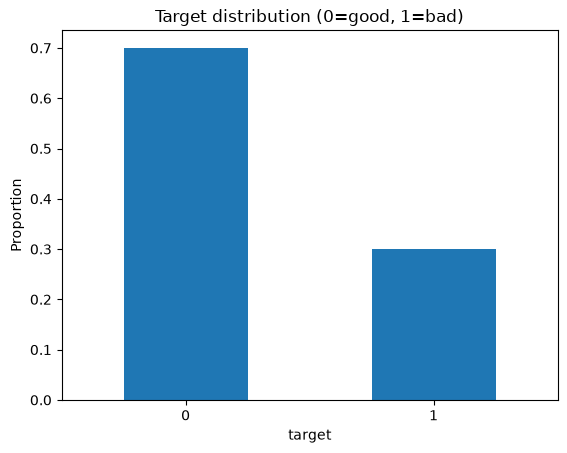

In [142]:
target_dist = df['target'].value_counts(normalize=True)
print(target_dist)

target_dist.plot(kind='bar', rot=0)
plt.title('Target distribution (0=good, 1=bad)')
plt.ylabel('Proportion')
plt.show()

## 4. Numeric features

7 numeric columns, but not all the same kind. `duration_months`, `credit_amount`, `age` are genuinely continuous, while `installment_rate`, `present_residence_since`, `existing_credits_count`, `num_people_liable` only take a handful of discrete values and are really more ordinal than continuous. Treat the histograms for those as counts per level.

In [143]:
numeric = df.select_dtypes(include='number').drop(columns='target')
categorical = df.select_dtypes(include='str')

print('Numeric:', list(numeric.columns))
print('Categorical:', list(categorical.columns))

Numeric: ['duration_months', 'credit_amount', 'installment_rate', 'present_residence_since', 'age', 'existing_credits_count', 'num_people_liable']
Categorical: ['checking_account_status', 'credit_history', 'purpose', 'savings_account', 'employment_duration', 'personal_status_sex', 'other_debtors_guarantors', 'property', 'other_installment_plans', 'housing', 'job', 'telephone', 'foreign_worker']


### 4.1 Distributions

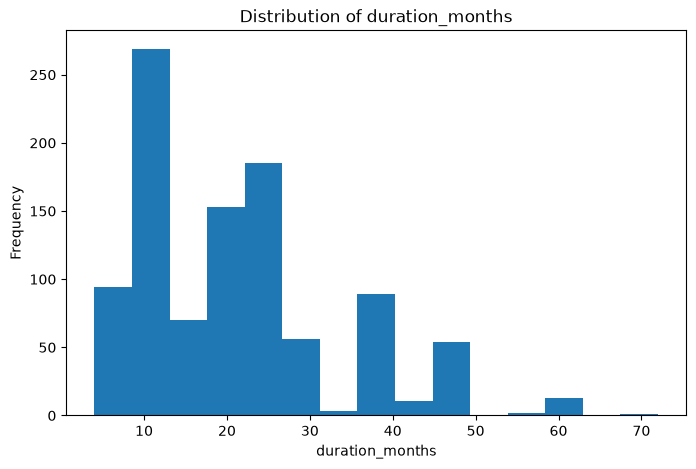

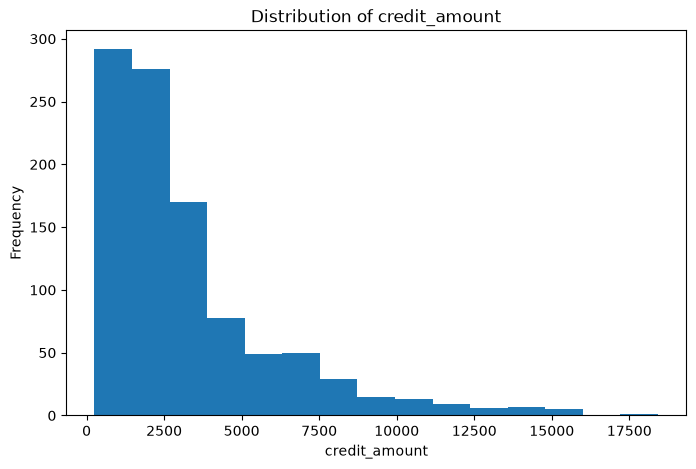

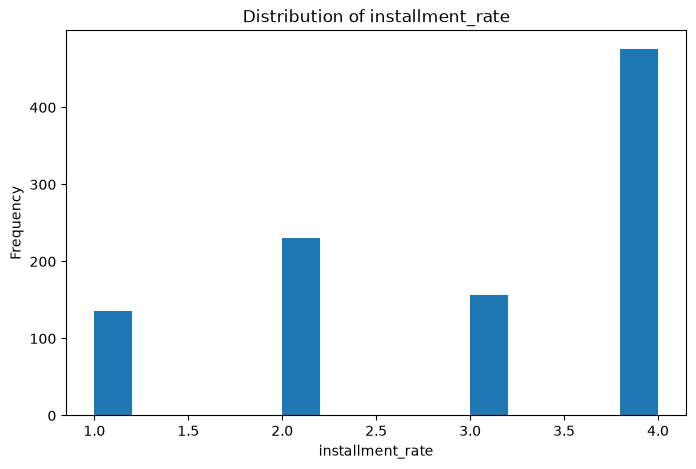

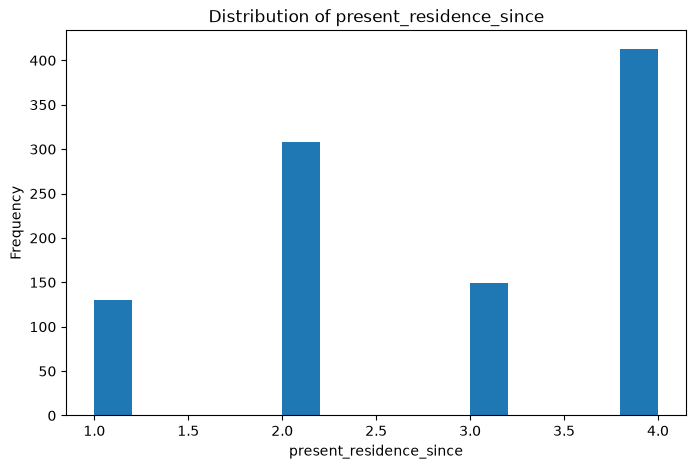

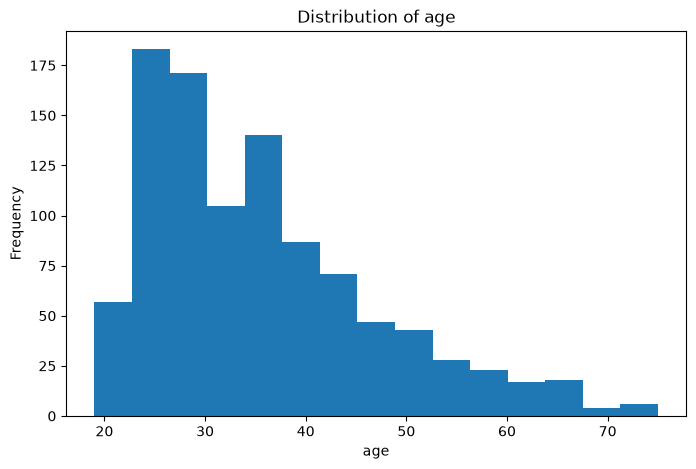

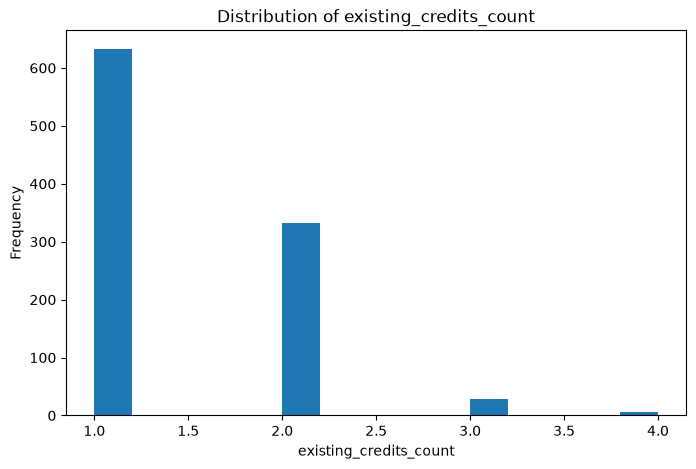

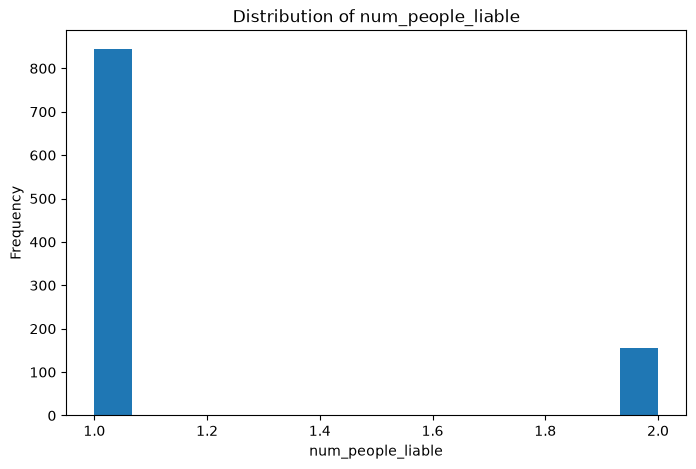

In [144]:
for col in numeric.columns:
    plt.figure(figsize=(8, 5))
    plt.hist(df[col], bins=15)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

`credit_amount` is probably going to come out heavily right-skewed (a handful of large loans pulling the tail out), `duration_months`/`age` more mildly so. If that's what shows up, it's a reason to log-transform them for the logistic regression pipeline later. Trees don't care about skew either way.

### 4.2 Good vs. bad

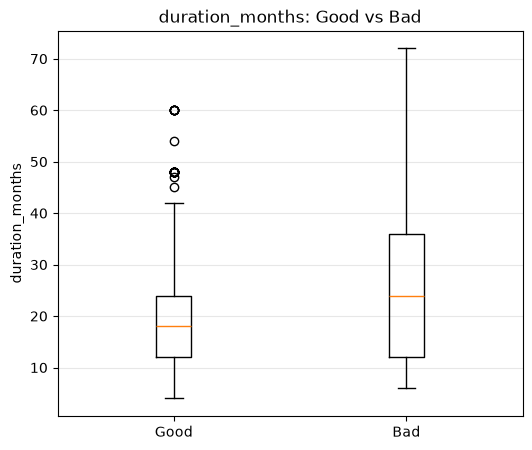

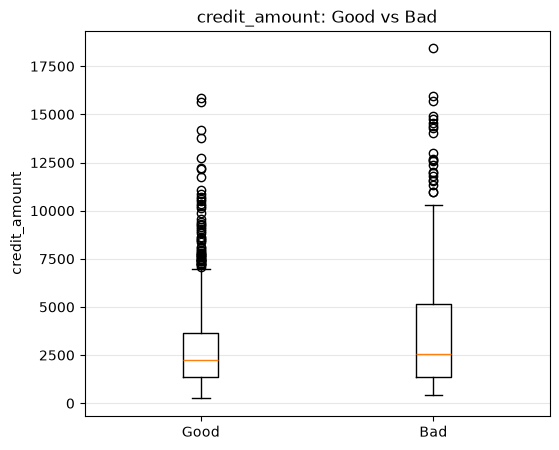

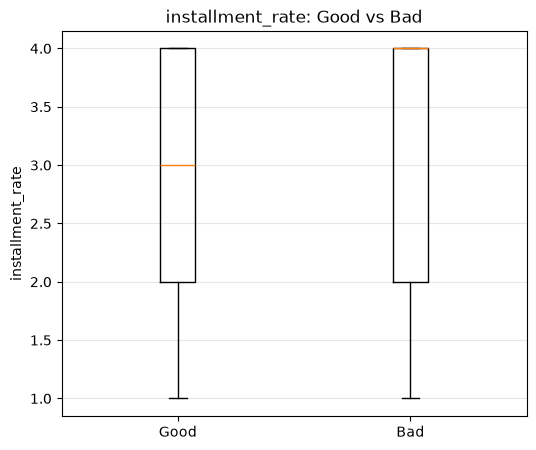

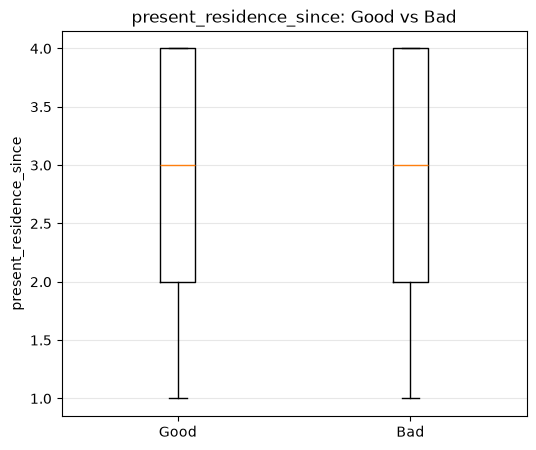

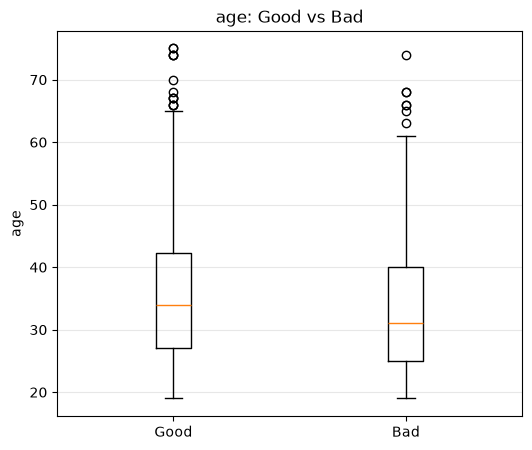

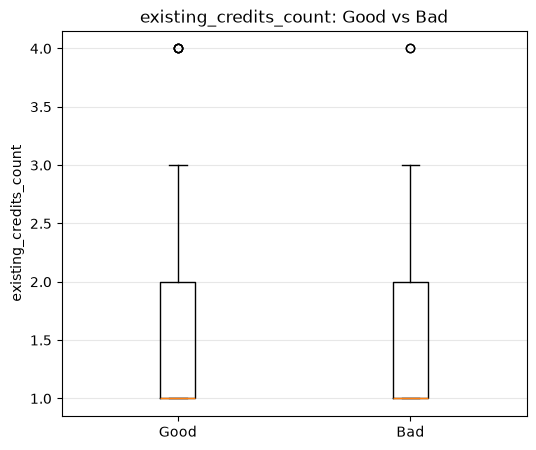

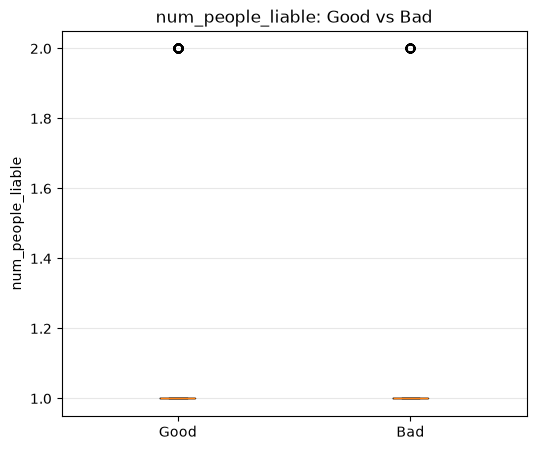

In [145]:
for col in numeric.columns:
    good = df[df['target'] == 0][col]
    bad = df[df['target'] == 1][col]

    plt.figure(figsize=(6, 5))
    plt.boxplot([good, bad], tick_labels=['Good', 'Bad'])
    plt.title(f'{col}: Good vs Bad')
    plt.ylabel(col)
    plt.grid(axis='y', alpha=0.3)
    plt.show()

### 4.3 Correlation with target

Pearson, so linear relationships only, and only the numeric columns. Says nothing about the 13 categorical ones, which is most of the dataset. Treat this as a first look, not the real ranking (section 6 puts it next to the categorical side).

In [146]:
corr = df.select_dtypes(include='number').corr()['target'].drop('target').sort_values(key=abs, ascending=False)
corr

duration_months            0.214927
credit_amount              0.154739
age                       -0.091127
installment_rate           0.072404
existing_credits_count    -0.045732
num_people_liable         -0.003015
present_residence_since    0.002967
Name: target, dtype: float64

## 5. Categorical features

13 columns, and this is where most of the signal in this dataset actually lives. `checking_account_status` especially shows up as the strongest predictor in pretty much every published analysis of German Credit.

### 5.1 checking_account_status

Looking at this one on its own first since it's expected to matter most.

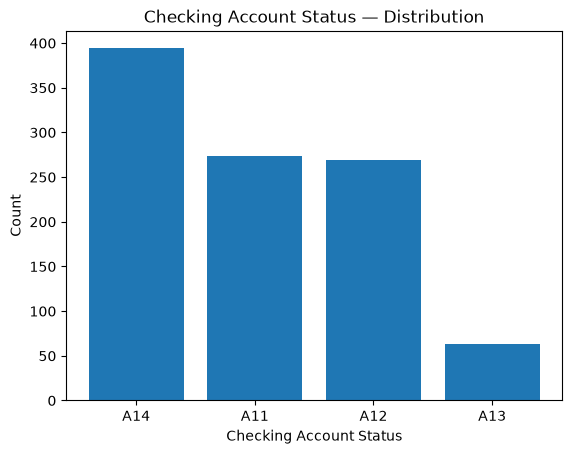

target                      0     1
checking_account_status            
A11                      50.7  49.3
A12                      61.0  39.0
A13                      77.8  22.2
A14                      88.3  11.7


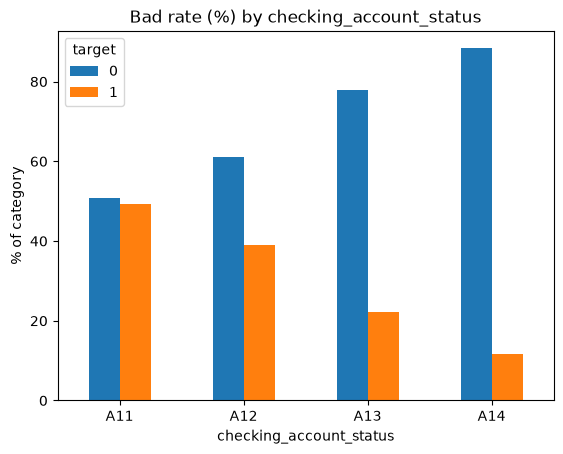

In [147]:
counts = df['checking_account_status'].value_counts()
plt.bar(counts.index, counts.values)
plt.xlabel('Checking Account Status')
plt.ylabel('Count')
plt.title('Checking Account Status — Distribution')
plt.show()

checking_target_pct = (
    pd.crosstab(df['checking_account_status'], df['target'], normalize='index') * 100
).round(1)
print(checking_target_pct)
checking_target_pct.plot(kind='bar', rot=0)
plt.title('Bad rate (%) by checking_account_status')
plt.ylabel('% of category')
plt.show()

### 5.2 Bad rate by category, everything else

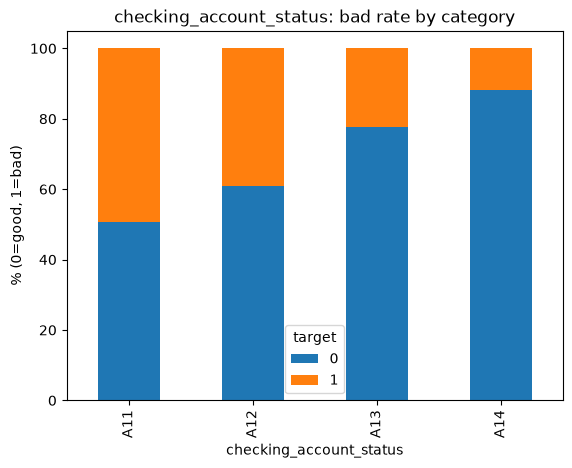

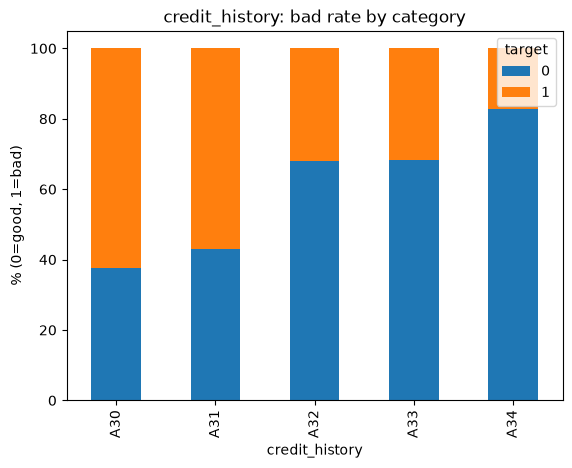

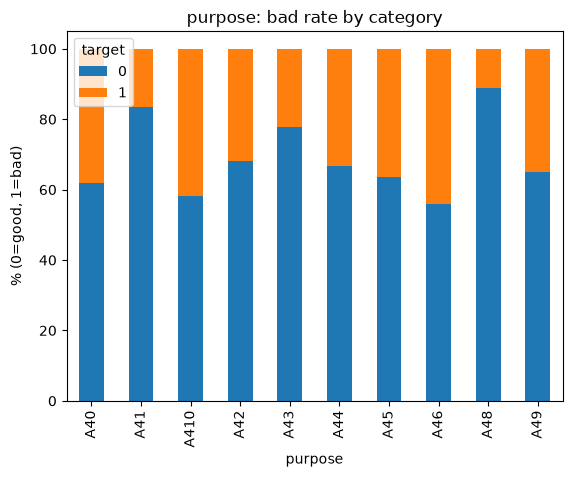

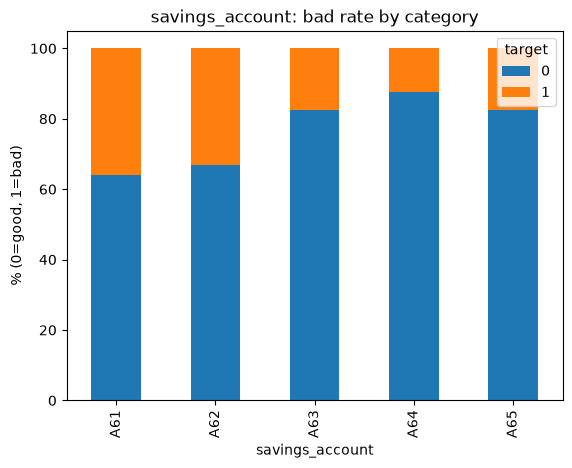

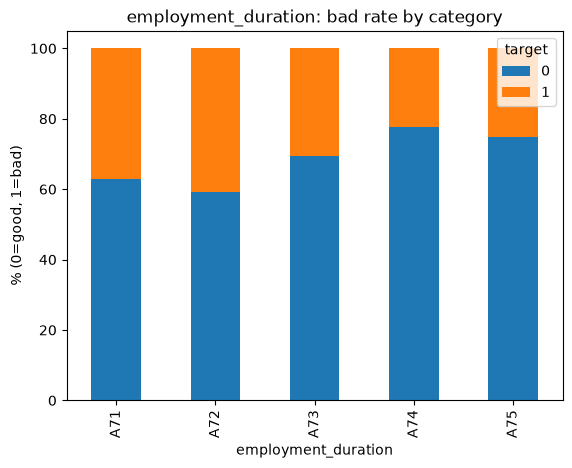

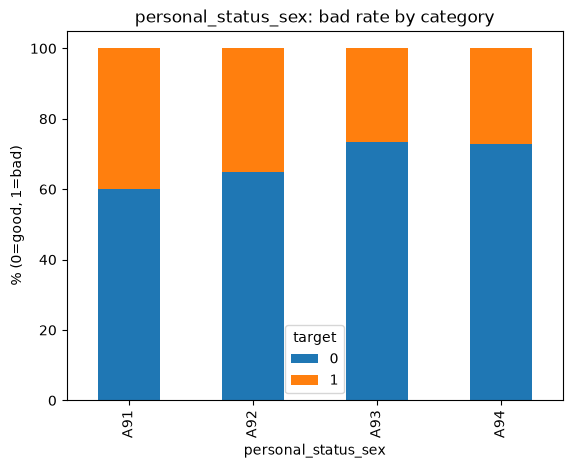

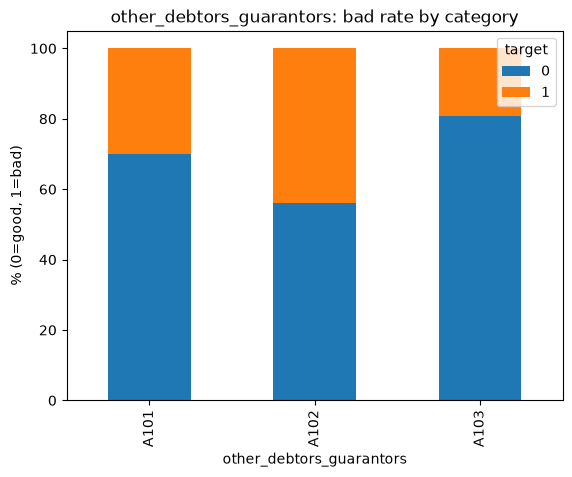

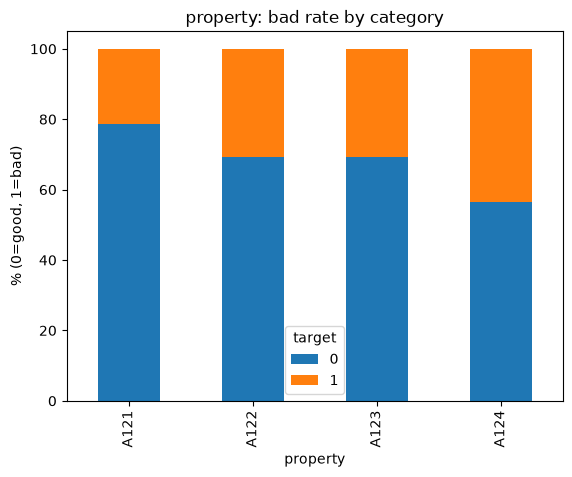

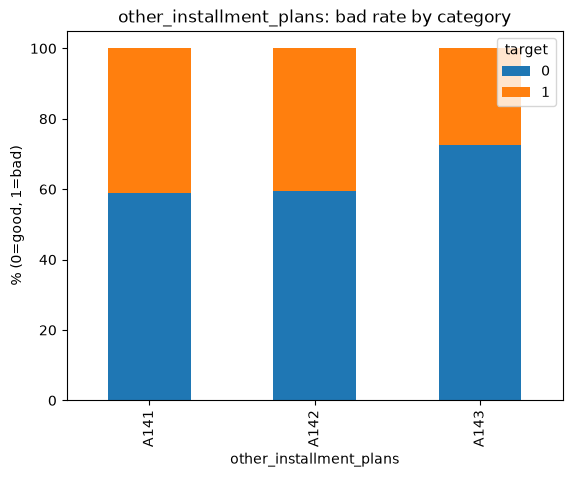

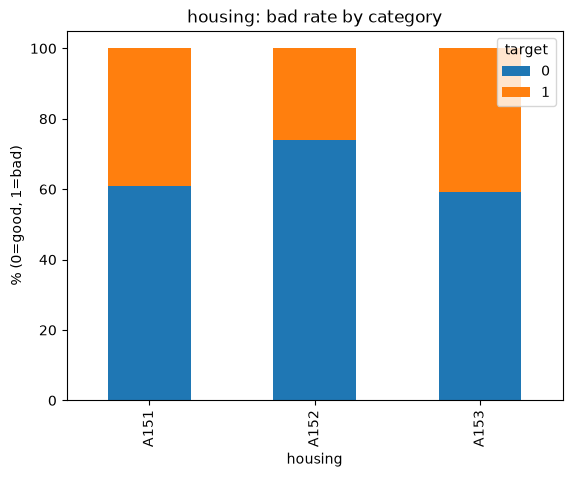

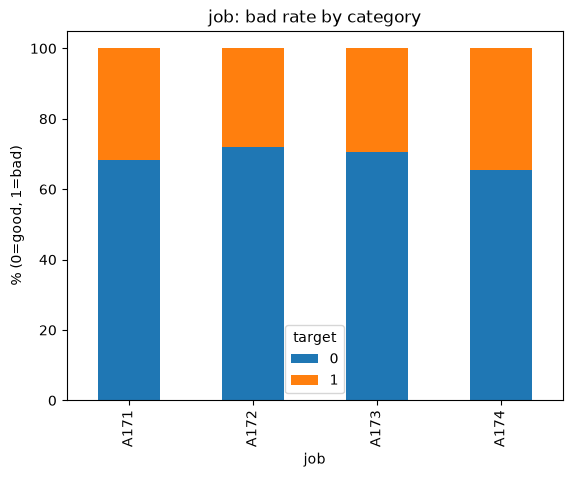

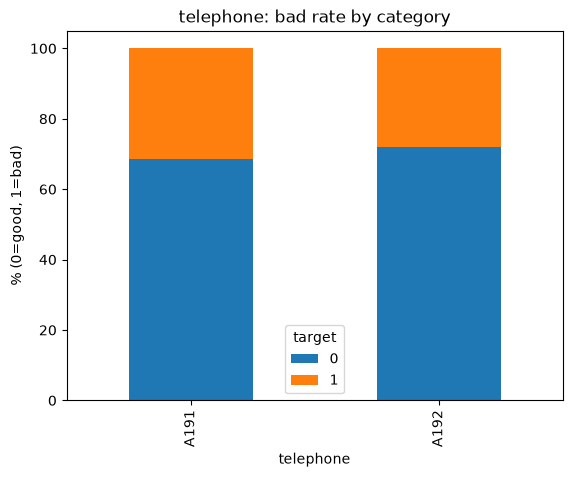

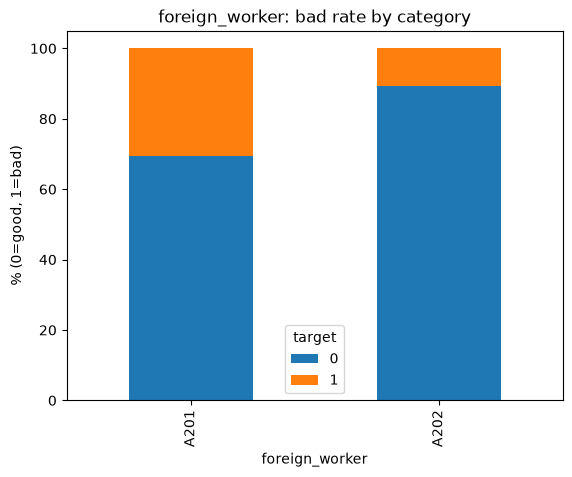

In [148]:
for col in categorical.columns:
    pct = (pd.crosstab(df[col], df['target'], normalize='index') * 100).round(1)
    pct.plot(kind='bar', stacked=True)
    plt.title(f'{col}: bad rate by category')
    plt.xlabel(col)
    plt.ylabel('% (0=good, 1=bad)')
    plt.show()

### 5.3 Cramér's V

Chi-square based association, 0 to 1. The categorical version of |correlation|, so it at least makes the 13 categorical columns comparable to each other.

In [149]:
def cramers_v(col, target):
    ct = pd.crosstab(col, target)
    chi2 = chi2_contingency(ct)[0]
    n = ct.sum().sum()
    return (chi2 / (n * (min(ct.shape) - 1))) ** 0.5

cat_assoc = pd.Series({c: cramers_v(df[c], df['target']) for c in categorical.columns})
cat_assoc = cat_assoc.sort_values(ascending=False)
cat_assoc

checking_account_status     0.351740
credit_history              0.248378
savings_account             0.189997
purpose                     0.182637
property                    0.154012
employment_duration         0.135530
housing                     0.134907
other_installment_plans     0.113310
personal_status_sex         0.098006
other_debtors_guarantors    0.081519
foreign_worker              0.076299
job                         0.043418
telephone                   0.034243
dtype: float64

## 6. Numeric vs. categorical, side by side

Not on the same scale, so this isn't a real merged ranking, just both lists next to each other as a first read before the actual SHAP-based feature selection later.

In [150]:
print('Numeric (|r| with target):')
print(corr.abs().sort_values(ascending=False))
print()
print("Categorical (Cramer's V with target):")
print(cat_assoc)

Numeric (|r| with target):
duration_months            0.214927
credit_amount              0.154739
age                        0.091127
installment_rate           0.072404
existing_credits_count     0.045732
num_people_liable          0.003015
present_residence_since    0.002967
Name: target, dtype: float64

Categorical (Cramer's V with target):
checking_account_status     0.351740
credit_history              0.248378
savings_account             0.189997
purpose                     0.182637
property                    0.154012
employment_duration         0.135530
housing                     0.134907
other_installment_plans     0.113310
personal_status_sex         0.098006
other_debtors_guarantors    0.081519
foreign_worker              0.076299
job                         0.043418
telephone                   0.034243
dtype: float64


## 7. Notes

checking_account_status is clearly the strongest single predictor, bad rate goes from 49.3% at A11 (no checking account) down to 11.7% at A14 (200 DM or more, or a salary account), way wider than any of the numeric correlations.

duration_months (r ≈ 0.21) and credit_amount (r ≈ 0.15) both correlate positively with default, which makes sense, longer and bigger loans are riskier. age (r ≈ -0.09) goes the other way, older applicants are a bit safer.

credit_amount looks skewed, worth log-transforming for the logistic regression branch.

Category meanings follow the corrected code table (Grömping, 2019, UCI "South German Credit"), not german.doc, which has 8 of the 13 categorical fields wrong. Under german.doc, A14 was "no checking account" and looked like the *safest* group, which made no sense. With the corrected labels the risk drops steadily from no account, through a negative balance, up to 200 DM or more. Two corrected labels still look odd and are worth a line in the thesis: property A124 (real estate) has the highest bad rate, and installment_rate code 4 (the lowest burden) has the highest bad rate of its four codes.

A47 (education, under the corrected table) doesn't appear at all in purpose.

Null check confirmed: every column has 0 missing values. Top categorical features by Cramér's V: checking_account_status (0.35), credit_history (0.25), savings_account (0.19), purpose (0.18), property (0.15).

### Feature grouping for preprocessing

| Feature | Group | Reason |
|---|---|---|
| `credit_amount` | Log + scale | Continuous positive variable with a right-skewed distribution; log transformation can reduce skew before scaling. |
| `duration_months` | Log + scale | Positive duration variable with right-skewed distribution; log transformation can reduce skew before scaling. |
| `age` | Scale | Numerical variable where relative magnitude matters, but log transformation is not necessary. |
| `installment_rate` | Scale | Bucket code for the installment as % of disposable income (1 = 35% or more, 2 = 25-35%, 3 = 20-25%, 4 = under 20%); ordered, so it is kept as a number. |
| `present_residence_since` | Scale | Bucket code for years at the current address (1 = under 1, 2 = 1-4, 3 = 4-7, 4 = 7 or more); ordered, kept as a number. |
| `existing_credits_count` | Scale | Bucket code for credits at this bank (1 = one, 2 = 2-3, 3 = 4-5, 4 = 6 or more); ordered, kept as a number. |
| `num_people_liable` | Scale | A flag, not a count: 1 = 0 to 2 dependants, 2 = 3 or more. |
| `job` | Ordinal | Categories have a meaningful progression in occupational skill/status. |
| `employment_duration` | Ordinal | Categories have a meaningful progression in length of employment. |
| `checking_account_status` | Nominal | Categories are account-status labels; the codes do not represent a simple numerical scale. |
| `credit_history` | Nominal | Categories describe different credit-history states rather than numerical values. |
| `purpose` | Nominal | Loan purposes are distinct categories with no natural ranking. |
| `savings_account` | Nominal | Categories represent savings-account/status ranges, but the unknown/no-account category breaks a simple ordinal interpretation. |
| `personal_status_sex` | Nominal | Categories represent demographic/status combinations with no meaningful order. |
| `other_debtors_guarantors` | Nominal | Categories represent different debtor/guarantor situations with no natural ranking. |
| `property` | Nominal | Property types are distinct categories rather than ordered values. |
| `other_installment_plans` | Nominal | Categories represent different installment-plan situations with no natural ranking. |
| `housing` | Nominal | Housing types are distinct categories with no natural order. |
| `telephone` | Nominal | Categories represent telephone status, not a numerical quantity. |
| `foreign_worker` | Nominal | Binary category describing worker status; there is no ordinal relationship. |